In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
cd ./drive/MyDrive/Churn_project_prediction

/content/drive/MyDrive/Churn_project_prediction


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("fivethirtyeight")
# import plotly.express as px
# import plotly.graph_objects as go

In [ ]:
ls

'Churn prediction.ipynb'   WA_Fn-UseC_-Telco-Customer-Churn.csv


In [ ]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df = df.drop(columns = ["customerID"])

In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df['gender'].unique()

array(['Female', 'Male'], dtype=object)

In [ ]:
for coln in df.columns:
  if coln not in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    print(f'=== Value counts for {coln} ===')
    print(df[coln].value_counts())
    print()

=== Value counts for gender ===
gender
Male      3555
Female    3488
Name: count, dtype: int64

=== Value counts for SeniorCitizen ===
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

=== Value counts for Partner ===
Partner
No     3641
Yes    3402
Name: count, dtype: int64

=== Value counts for Dependents ===
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

=== Value counts for PhoneService ===
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

=== Value counts for MultipleLines ===
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

=== Value counts for InternetService ===
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

=== Value counts for OnlineSecurity ===
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

=== Value counts for OnlineBackup ===
OnlineBac

In [ ]:
gender_counts = df['gender'].value_counts()
display(gender_counts)

,count
gender,
Male,3555
Female,3488


In [ ]:
senior_by_gender = pd.crosstab(df['gender'], df['SeniorCitizen'], margins=True)
display(senior_by_gender)
print('\nPercentage Distribution:')
display(pd.crosstab(df['gender'], df['SeniorCitizen'], normalize='index') * 100)

SeniorCitizen,0,1,All
gender,,,
Female,2920,568,3488
Male,2981,574,3555
All,5901,1142,7043



Percentage Distribution:


SeniorCitizen,0,1
gender,,
Female,83.715596,16.284404
Male,83.853727,16.146273


In [ ]:
StreamingTV_by_gender = pd.crosstab(df['gender'], df['StreamingTV'], margins=True)
display(StreamingTV_by_gender)
print('\nPercentage Distribution:')
display(pd.crosstab(df['gender'], df['StreamingTV'], normalize='index') * 100)

StreamingTV,No,No internet service,Yes,All
gender,,,,
Female,1386,747,1355,3488
Male,1424,779,1352,3555
All,2810,1526,2707,7043



Percentage Distribution:


StreamingTV,No,No internet service,Yes
gender,,,
Female,39.736239,21.416284,38.847477
Male,40.056259,21.912799,38.030942


In [ ]:
for coln in df.columns:
  if coln not in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    print(coln, df[coln].unique())
    print('==========================================================')

gender ['Female' 'Male']
SeniorCitizen [0 1]
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn ['No' 'Yes']


In [ ]:
for coln in df.columns:
  if coln not in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    print(f'=== Value counts for {coln} by gender ===')
    coln_by_gender = pd.crosstab(df['gender'], df[coln], margins=True)
    display(coln_by_gender)
    print()

=== Value counts for gender by gender ===


gender,Female,Male,All
gender,,,
Female,3488,0,3488
Male,0,3555,3555
All,3488,3555,7043



=== Value counts for SeniorCitizen by gender ===


SeniorCitizen,0,1,All
gender,,,
Female,2920,568,3488
Male,2981,574,3555
All,5901,1142,7043



=== Value counts for Partner by gender ===


...

PaperlessBilling,No,Yes,All
gender,,,
Female,1402,2086,3488
Male,1470,2085,3555
All,2872,4171,7043



=== Value counts for PaymentMethod by gender ===


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check,All
gender,,,,,
Female,788,752,1170,778,3488
Male,756,770,1195,834,3555
All,1544,1522,2365,1612,7043



=== Value counts for Churn by gender ===


Churn,No,Yes,All
gender,,,
Female,2549,939,3488
Male,2625,930,3555
All,5174,1869,7043


In [ ]:
for coln in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    print(coln, len(df[df[coln]==" "]))
    print('==========================================================')

tenure 0
MonthlyCharges 0
TotalCharges 11


In [ ]:
for coln in df.columns:
    print(coln, len(df[df[coln]==" "]))
    print('==========================================================')

gender 0
SeniorCitizen 0
Partner 0
Dependents 0
tenure 0
PhoneService 0
MultipleLines 0
InternetService 0
OnlineSecurity 0
OnlineBackup 0
DeviceProtection 0
TechSupport 0
StreamingTV 0
StreamingMovies 0
Contract 0
PaperlessBilling 0
PaymentMethod 0
MonthlyCharges 0
TotalCharges 11
Churn 0


In [ ]:
df["TotalCharges"] = df["TotalCharges"].replace({" ": "0.0"}).astype(float)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


In [ ]:
def plot_distribution(df, column_name):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    sns.histplot(df[column_name], kde = True)
    plt.title(f'Distribution of {column_name}')

    col_mean = df[column_name].mean()
    col_median = df[column_name].median()
    col_mode = df[column_name].mode()[0]
    plt.axvline(col_mean, color='r', linestyle='dashed', linewidth=2, label='Mean')
    plt.axvline(col_median, color='g', linestyle='dashed', linewidth=2, label='Median')
    plt.axvline(col_mode, color='b', linestyle='dashed', linewidth=2, label='Mode')
    plt.legend()

    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[column_name])
    plt.title(f'Boxplot of {column_name}')

    plt.show()

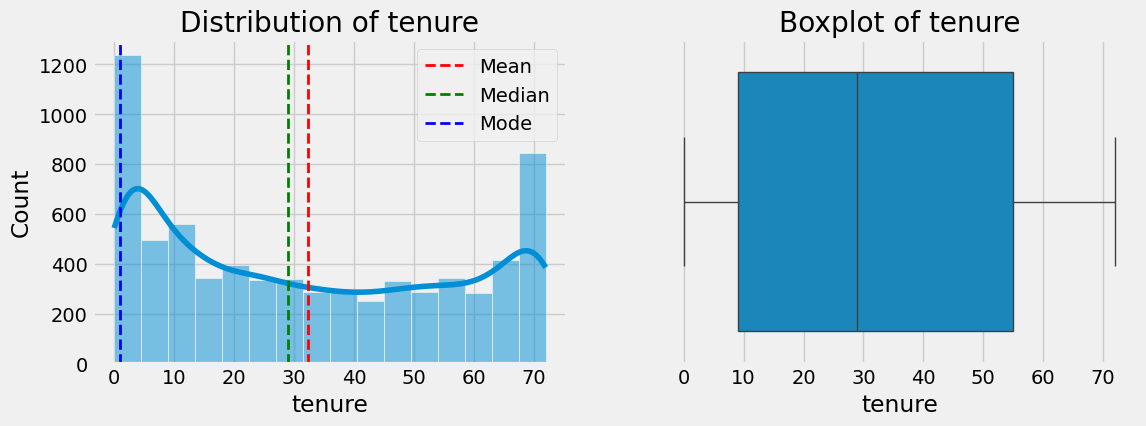

In [ ]:
plot_distribution(df, "tenure")

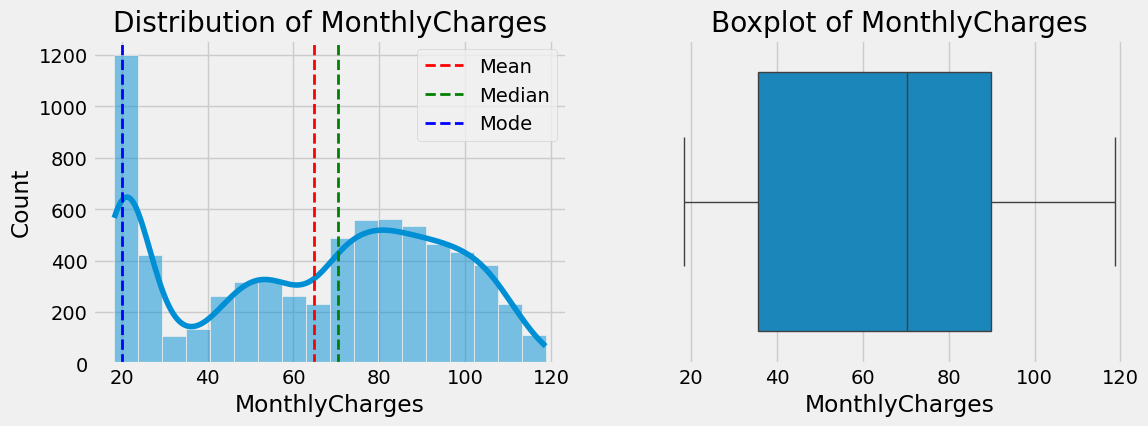

In [ ]:
plot_distribution(df, "MonthlyCharges")

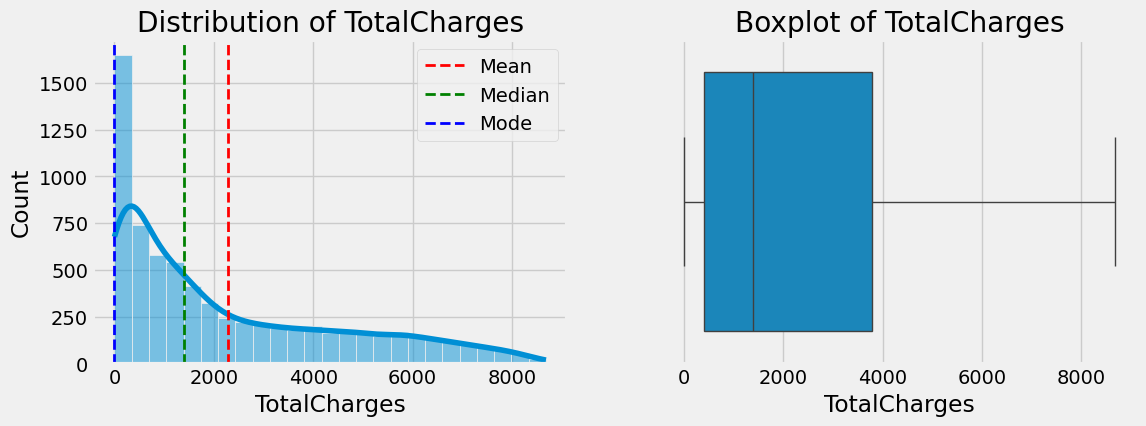

In [ ]:
plot_distribution(df, "TotalCharges")

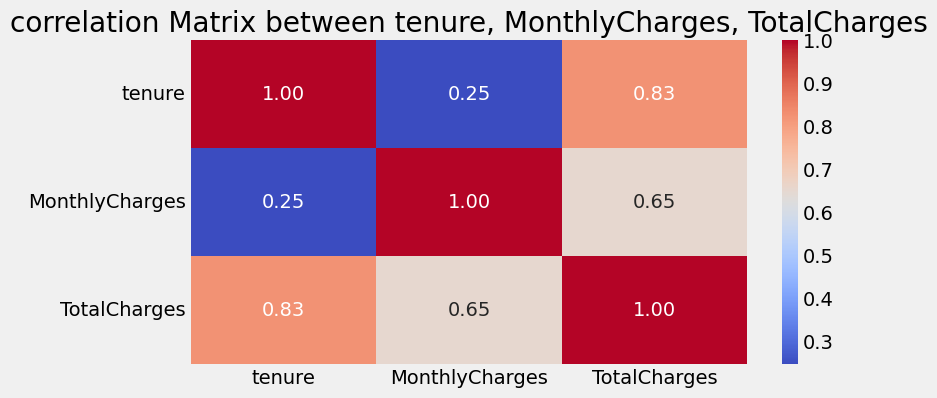

In [ ]:
plt.figure(figsize=(8, 4))
sns.heatmap(df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr(),annot=True,cmap = "coolwarm", fmt ='.2f' )
plt.title("correlation Matrix between tenure, MonthlyCharges, TotalCharges")
plt.show()


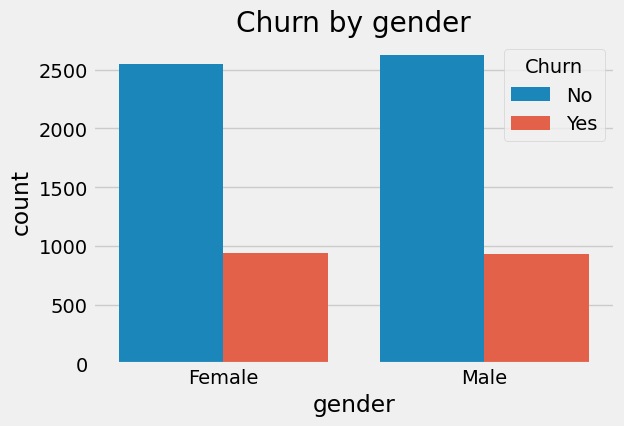

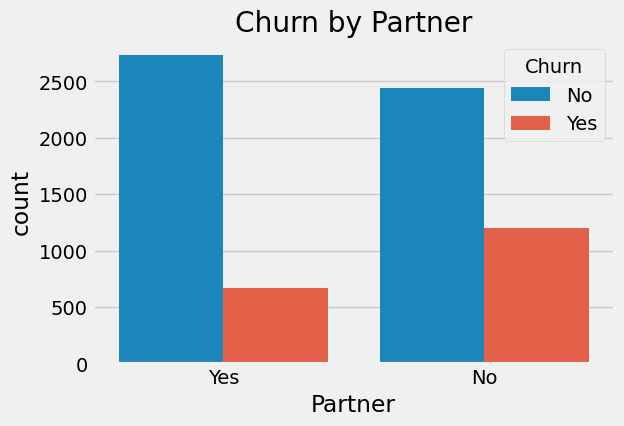

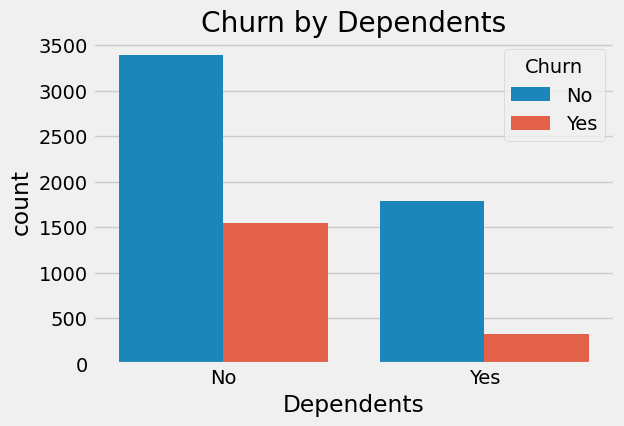

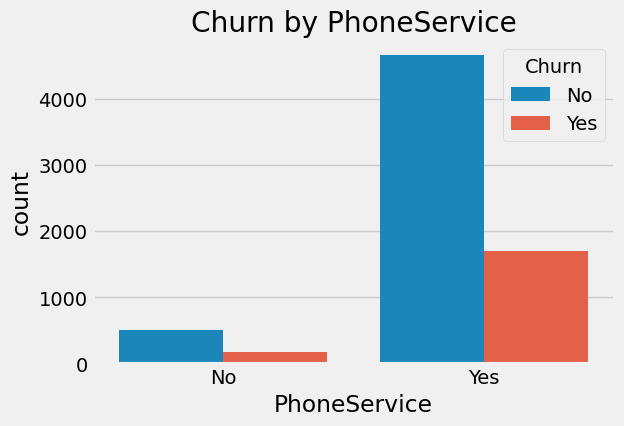

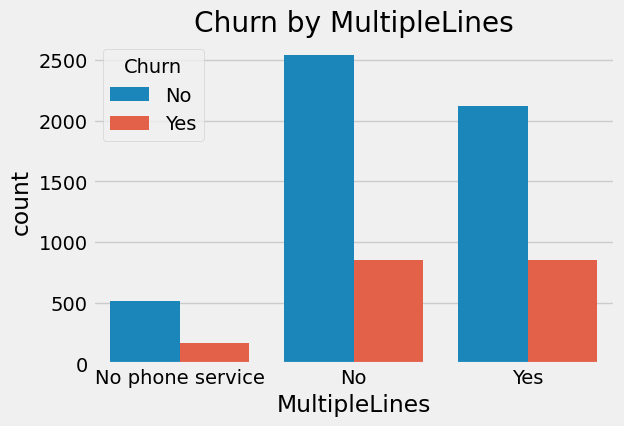

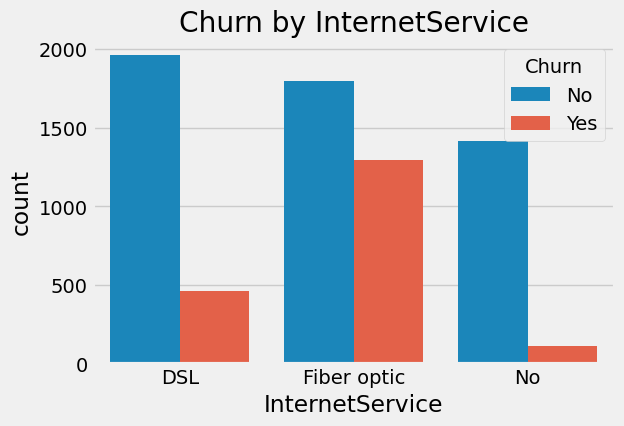

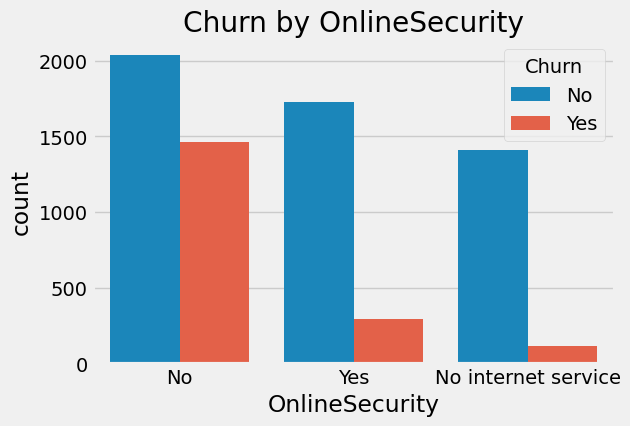

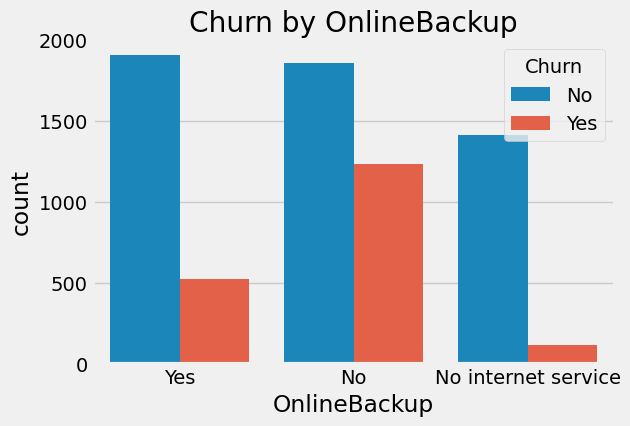

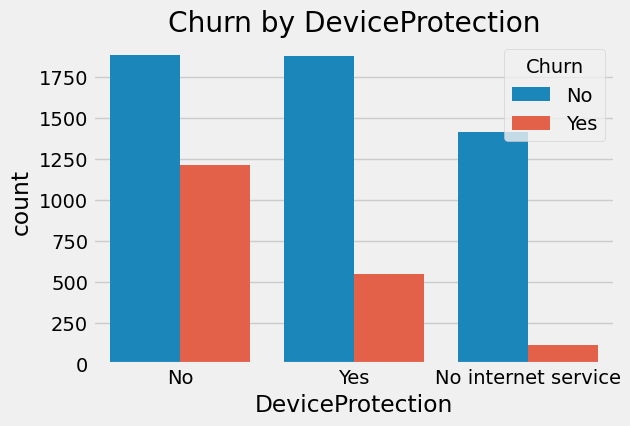

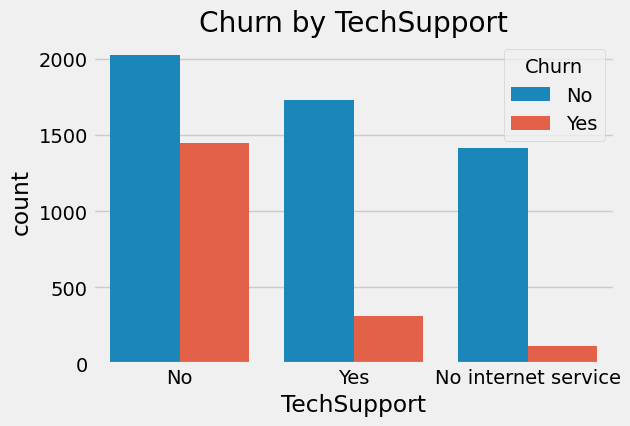

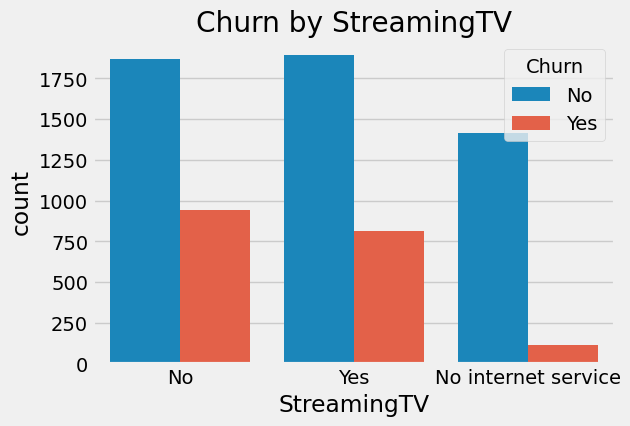

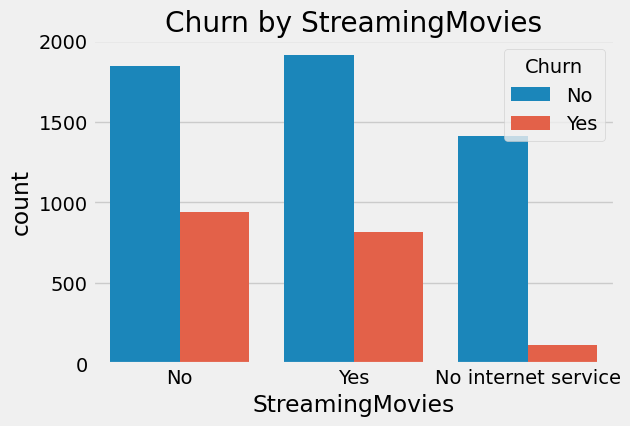

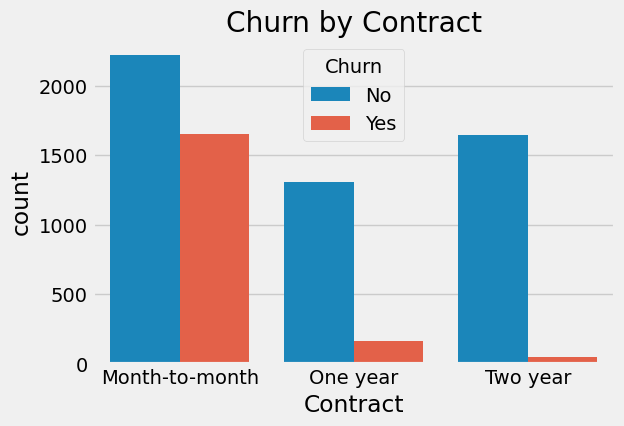

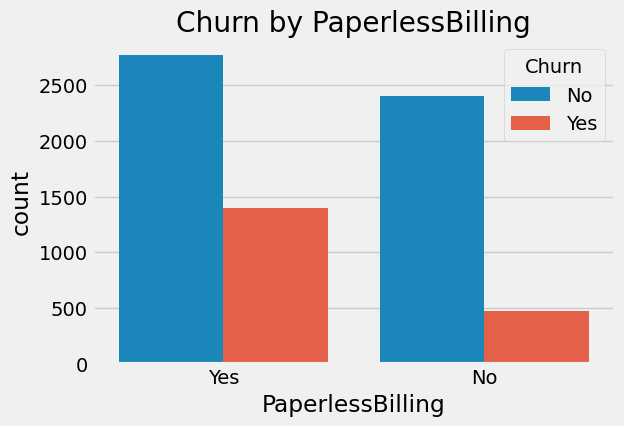

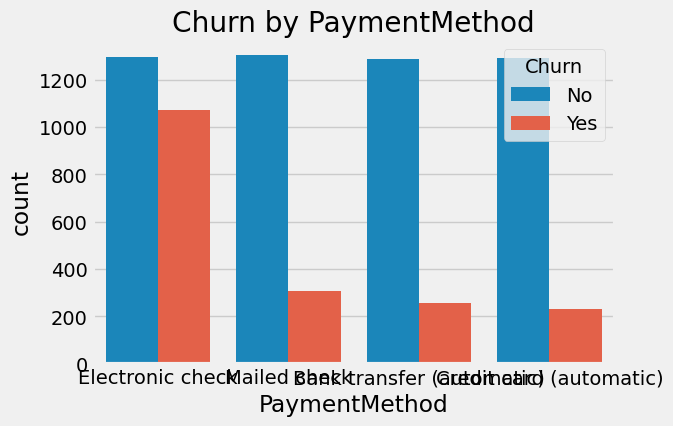

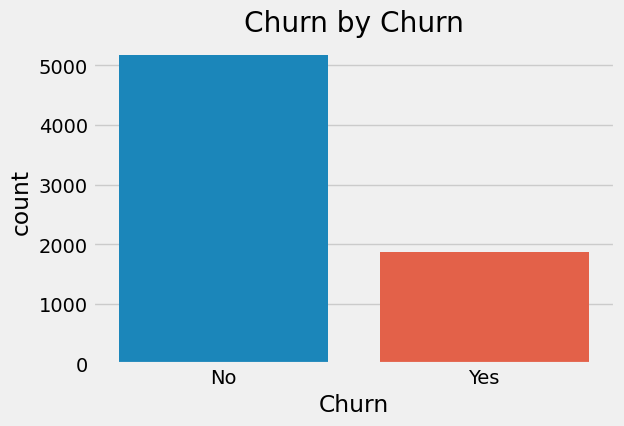

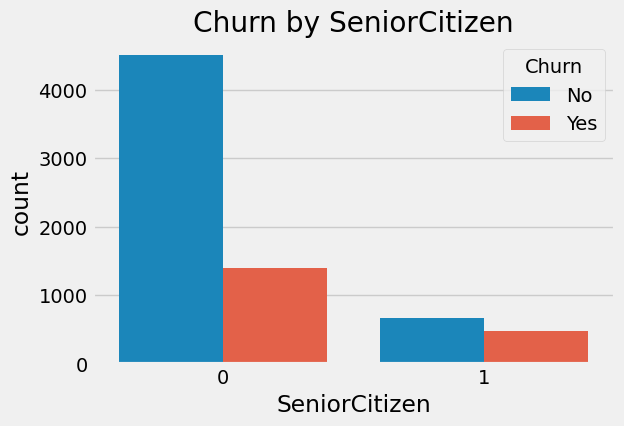

In [ ]:
categorical_data_colns = df.select_dtypes(include = "object").columns.to_list() + ["SeniorCitizen"]

for coln in categorical_data_colns:
  plt.figure(figsize = (6, 4))
  sns.countplot(data = df, x = coln, hue = "Churn")
  plt.title(f"Churn by {coln}")
  plt.show()

# OBSERVATION
It can be concluded that from non-numerical/categorical data columnm,
The the number fo customers that will not churn is more that the one that will churn with a very large margin.

#conclusion
This shows a class imbalance in the data set. This may cause overfitting on the most seen/ occuring data which is 'Churn' and underfit on 'will not churn'.

There might be a need for balancing of data set

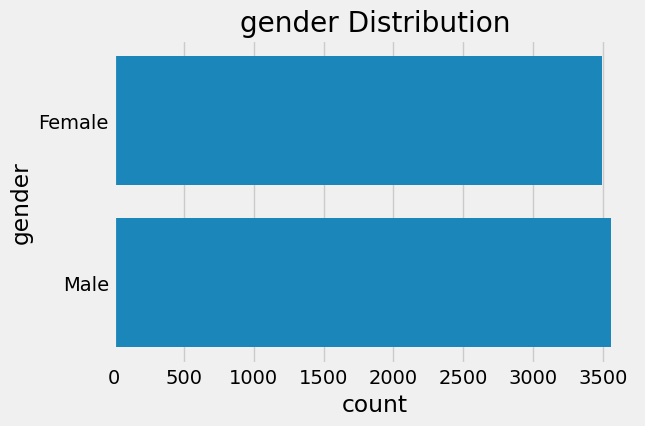

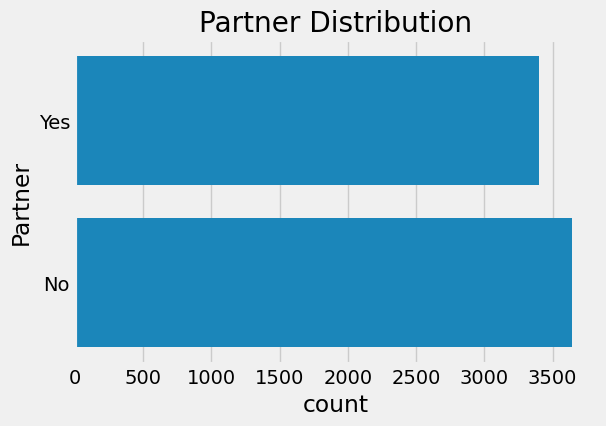

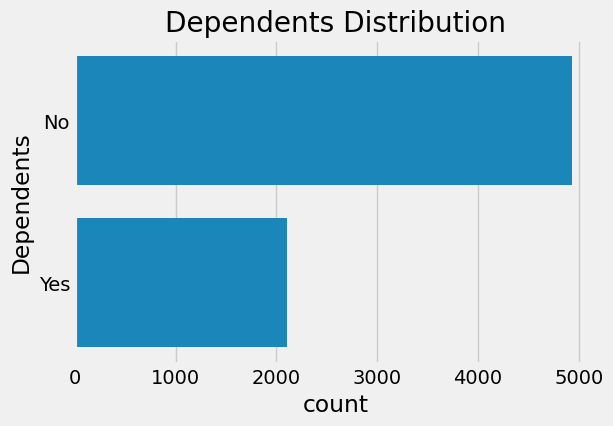

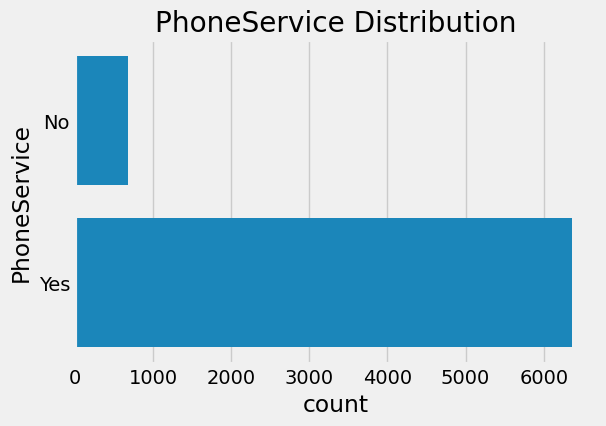

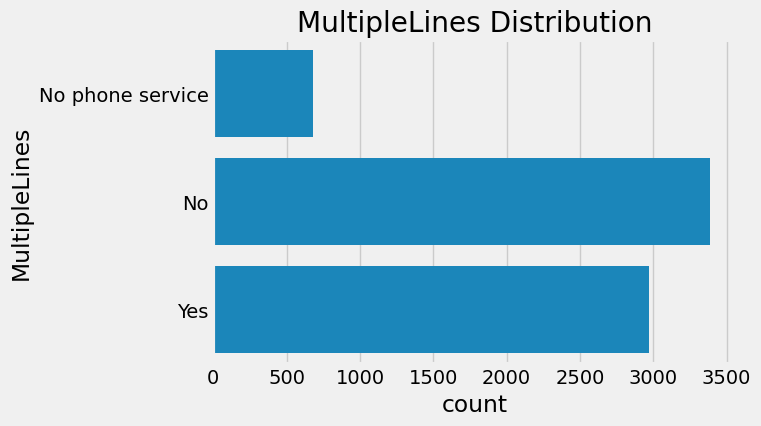

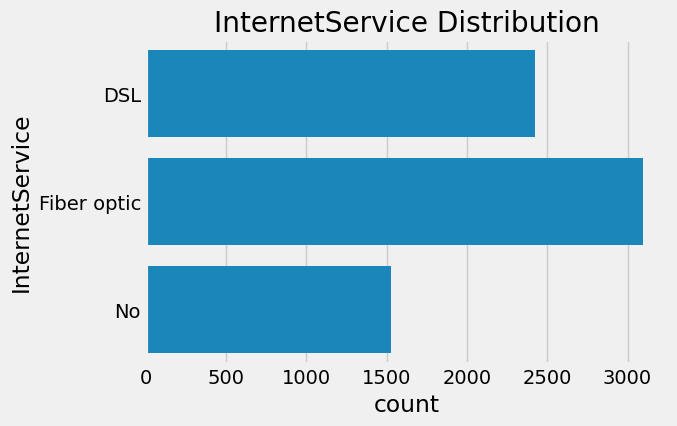

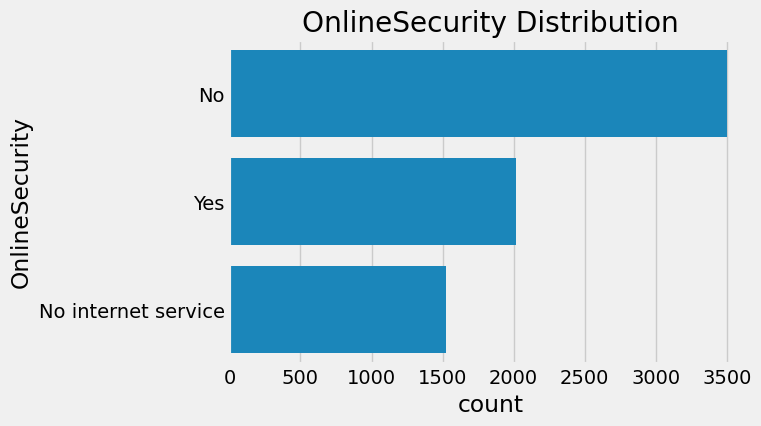

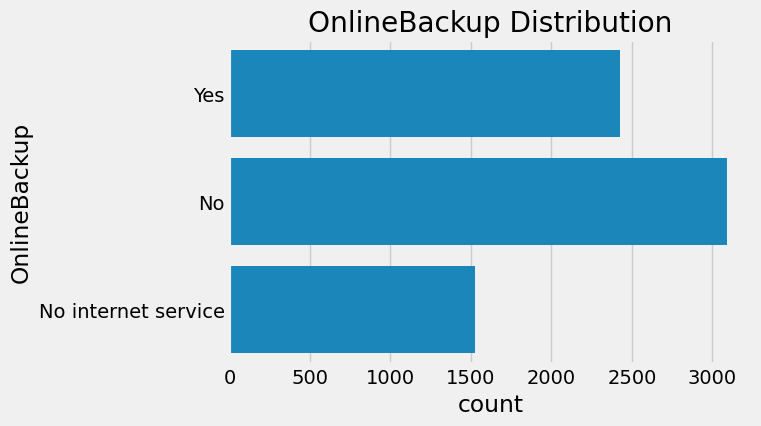

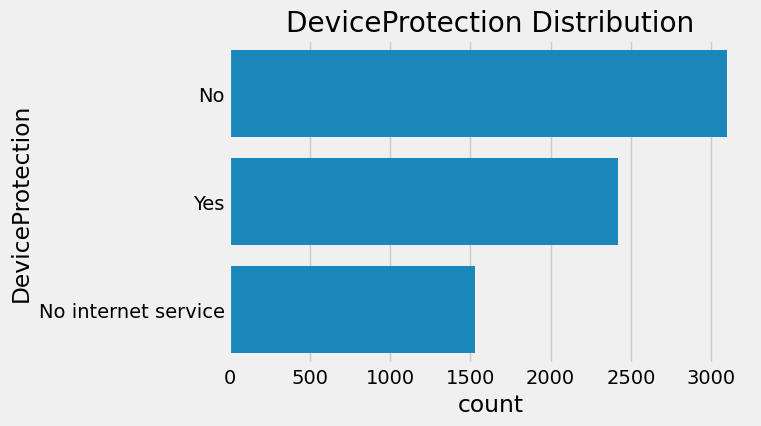

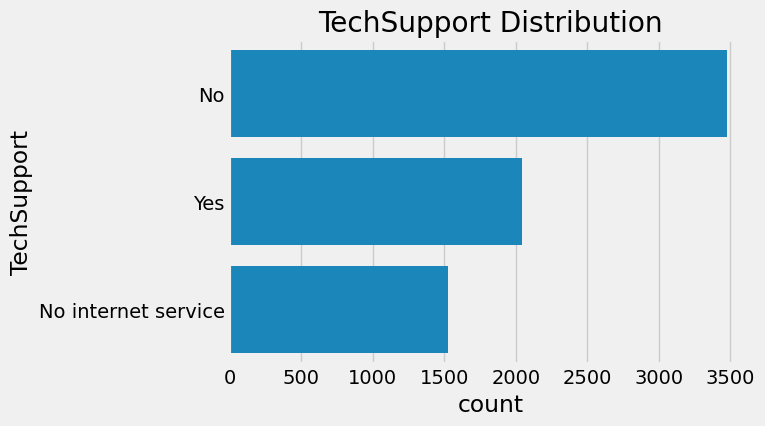

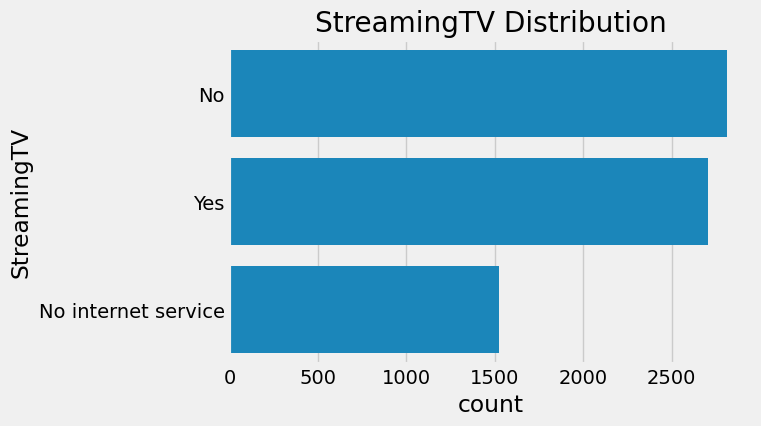

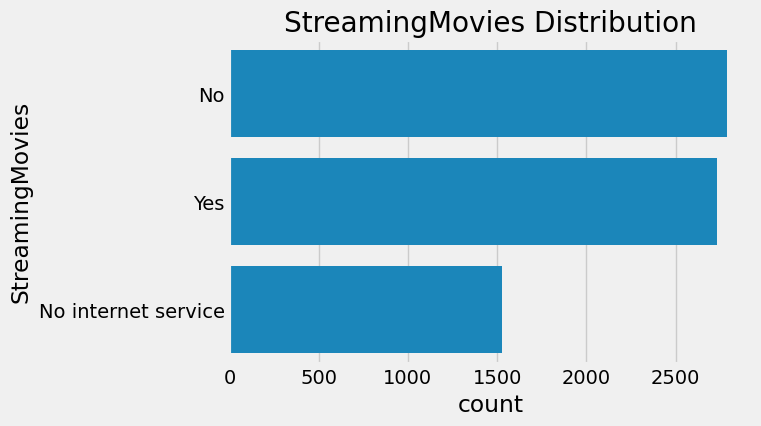

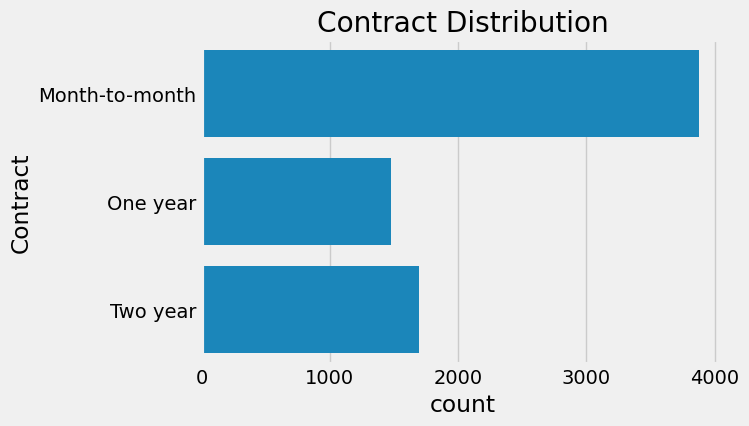

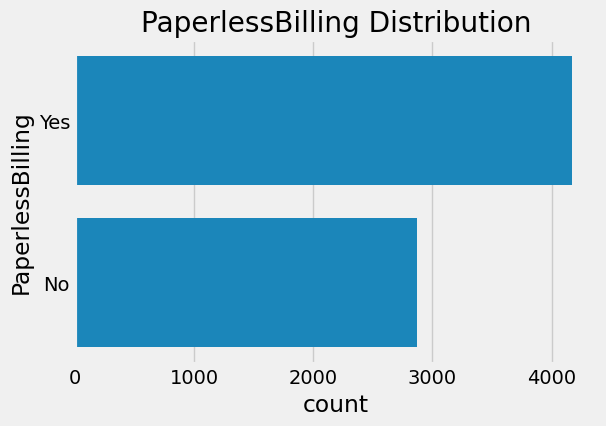

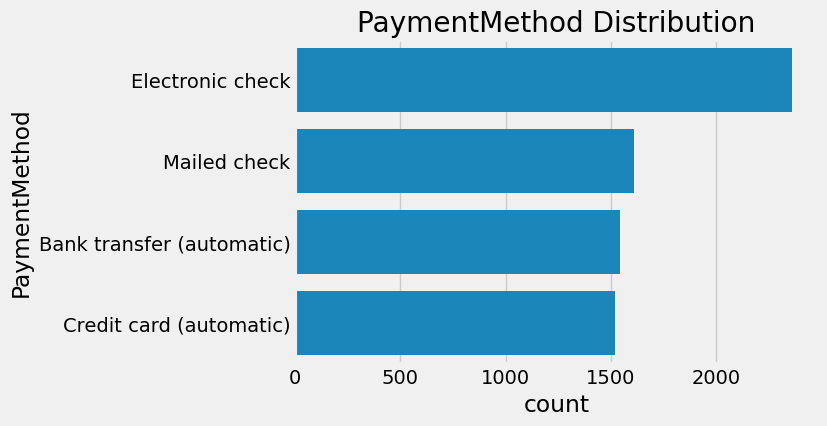

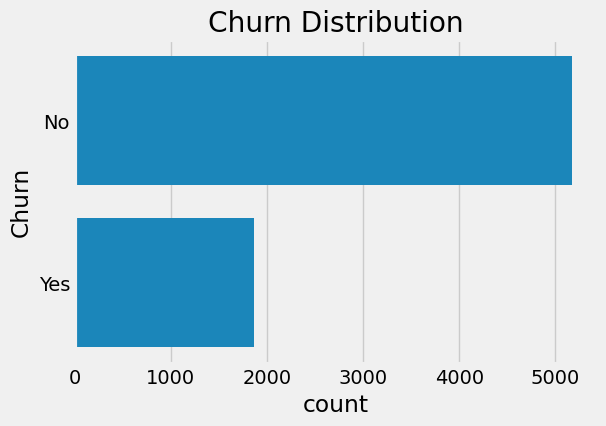

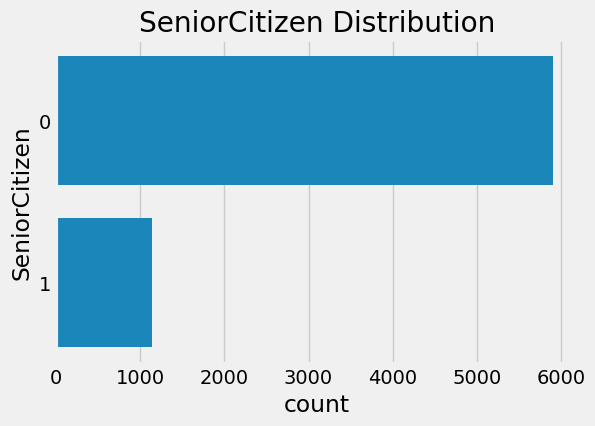

In [ ]:
for coln in categorical_data_colns:
  plt.figure(figsize = (6, 4))
  sns.countplot(y = df[coln])
  plt.title(f"{coln} Distribution")
  plt.show()

#LABEL ENCODING

In [ ]:
df['Churn'] = df['Churn'].replace({"Yes": 1, "No": 0})

/tmp/ipykernel_1459/196801821.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Churn'] = df['Churn'].replace({"Yes": 1, "No": 0})


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [ ]:
objects_colns = df.select_dtypes(include = "object").columns

In [ ]:
objects_colns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

#ENCODING - categorical data columns

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoders = {}

for coln in objects_colns:
    label_encoder = LabelEncoder()
    df[coln] = label_encoder.fit_transform(df[coln])
    encoders[coln] = label_encoder

In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [ ]:
encoders

{'gender': LabelEncoder(),
 'Partner': LabelEncoder(),
 'Dependents': LabelEncoder(),
 'PhoneService': LabelEncoder(),
 'MultipleLines': LabelEncoder(),
 'InternetService': LabelEncoder(),
 'OnlineSecurity': LabelEncoder(),
 'OnlineBackup': LabelEncoder(),
 'DeviceProtection': LabelEncoder(),
 'TechSupport': LabelEncoder(),
 'StreamingTV': LabelEncoder(),
 'StreamingMovies': LabelEncoder(),
 'Contract': LabelEncoder(),
 'PaperlessBilling': LabelEncoder(),
 'PaymentMethod': LabelEncoder()}

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   int64  
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   int64  
 3   Dependents        7043 non-null   int64  
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   int64  
 6   MultipleLines     7043 non-null   int64  
 7   InternetService   7043 non-null   int64  
 8   OnlineSecurity    7043 non-null   int64  
 9   OnlineBackup      7043 non-null   int64  
 10  DeviceProtection  7043 non-null   int64  
 11  TechSupport       7043 non-null   int64  
 12  StreamingTV       7043 non-null   int64  
 13  StreamingMovies   7043 non-null   int64  
 14  Contract          7043 non-null   int64  
 15  PaperlessBilling  7043 non-null   int64  
 16  PaymentMethod     7043 non-null   int64  


In [ ]:
import pickle
with open("encoder.pkl", "wb") as f:
      pickle.dump(encoders, f)

In [ ]:
ls

'Churn prediction.ipynb'   encoder.pkl   WA_Fn-UseC_-Telco-Customer-Churn.csv


#SCALING/ NORMALIZATION -- Numerical data columns

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
numerical_colns = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()
df[numerical_colns] = scaler.fit_transform(df[numerical_colns])

In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,-1.277445,0,1,0,0,2,0,0,0,0,0,1,2,-1.160323,-0.992611,0
1,1,0,0,0,0.066327,1,0,0,2,0,2,0,0,0,1,0,3,-0.259629,-0.172165,0
2,1,0,0,0,-1.236724,1,0,0,2,2,0,0,0,0,0,1,3,-0.362660,-0.958066,1
3,1,0,0,0,0.514251,0,1,0,2,0,2,2,0,0,1,0,0,-0.746535,-0.193672,0
4,0,0,0,0,-1.236724,1,0,1,0,0,0,0,0,0,0,1,2,0.197365,-0.938874,1


#RECTIFYING CLASS IMBALANCE

In [ ]:
df["Churn"].value_counts()

,count
Churn,
0,5174
1,1869


In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

In [ ]:
x = df.drop(columns = ["Churn"])
y = df["Churn"]

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [ ]:
y_train.value_counts()

,count
Churn,
0,4138
1,1496


In [ ]:
smote = SMOTE(random_state= 42)

In [ ]:
#rectifying class imbalance by performing oversampling using the SMOTE function
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

In [ ]:
y_train_smote.value_counts(
)

,count
Churn,
0,4138
1,4138


In [ ]:
models = {
    "Random Forest" : RandomForestClassifier(random_state = 42),
    "XGBoost": XGBClassifier(random_state = 42)
}

In [ ]:
hyperparameters = {
      "Random Forest":{
          "n_estimators": [100,200,300],
          "max_depth": [5, 10, None]
      },
      "XGBoost":{
          "learning_rate": [ 0.2, 0.3, 0.4],
          "max_depth": [3, 5, 7]
      }
}

In [ ]:
best_models = {}
for model_name, model in models.items():
    print(f"Tunning {model_name}................")
    grid = GridSearchCV(estimator = model, param_grid=hyperparameters[model_name], cv=5, scoring = "accuracy")
    grid.fit(x_train_smote, y_train_smote)
    best_models[model_name] = grid.best_estimator_
    print(f"Best parameters for {model_name}: {grid.best_params_}")
    print(f"Best accuracy for {model_name}: {grid.best_score_: .2f}\n")




Tunning Random Forest................
Best parameters for Random Forest: {'max_depth': None, 'n_estimators': 200}
Best accuracy for Random Forest:  0.84

Tunning XGBoost................
Best parameters for XGBoost: {'learning_rate': 0.3, 'max_depth': 7}
Best accuracy for XGBoost:  0.83



In [ ]:
best_models

{'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric=None, feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=0.3, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=None,
               n_jobs=None, num_parallel_tree=None, ...)}

In [ ]:
with open("best_model.pkl", "wb") as f:
    pickle.dump(best_models['Random Forest'], f)


In [ ]:
with open("scaler.pkl", "wb") as f:
  pickle.dump(scaler, f)

# The .pkl file (encoder, scaler and best model) are created to be resused when building an app for deployment

In [ ]:
ls

 best_model.pk             encoder.pkl
 best_model.pkl            scaler.pkl
'Churn prediction.ipynb'   WA_Fn-UseC_-Telco-Customer-Churn.csv


In [ ]:
y_test_pred = best_models['Random Forest'].predict(x_test)
y_test_prob = best_models['Random Forest'].predict_proba(x_test)[:, 1]

In [ ]:
print(f"predicted values: {y_test_pred}")
print(f"prediction probability: {y_test_prob}")

predicted values: [1 0 0 ... 0 0 0]
prediction probability: [0.915 0.42  0.01  ... 0.    0.02  0.35 ]


In [ ]:
prediction_accuracy = accuracy_score(y_test,y_test_pred)
prediction_ROC = roc_auc_score(y_test,y_test_pred)
prediction_confusionMatrix = confusion_matrix(y_test,y_test_pred)
prediction_ClassificationReport = classification_report(y_test,y_test_pred)


In [ ]:
print(f"prediction accuracy: {prediction_accuracy}")
print(f"prediction ROC: {prediction_ROC}")
print(f"prediction Confussion Matrix:\n {prediction_confusionMatrix}")
print(f"prediction Classification Report:\n{prediction_ClassificationReport}")

prediction accuracy: 0.7785663591199432
prediction ROC: 0.7456201413976212
prediction Confussion Matrix:
 [[845 191]
 [121 252]]
prediction Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1036
           1       0.57      0.68      0.62       373

    accuracy                           0.78      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.78      0.78      1409



In [ ]:
with open("best_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)
with open("encoder.pkl", "rb") as f:
    encoders = pickle.load(f)
with open("scaler.pkl", "rb") as f:
    scaler_data = pickle.load(f)


In [ ]:
numerical_colns

['tenure', 'MonthlyCharges', 'TotalCharges']

In [ ]:
def make_prediction(input_data):
    input_df = pd.Dataframe([input_data])
    for coln, encoder in encoders.items():
        input_df[coln] = encoder.transform(input_df[coln])
    numerical_colns = ['tenure', 'MonthlyCharges', 'TotalCharges']
    input_df[numerical_colns] = scaler_data.transform(input_df[numerical_colns])
    prediction = loaded_model.predict(input_df)[0]
    probability = loaded_model.predict_proba(input_df)[0,1]
    return "Churn" if prediction == 1 else "No Churn", probability


In [ ]:
df.columns

In [ ]:
example_input = {
    "gender": "Female",
    'SeniorCitizen': 0,
    'Partner': "Yes",
    'Dependents': "No",
    'tenure': 1,
    'PhoneService': "No",
    'MultipleLines': "No phone services",
    'InternetService':"DSL" ,
    'OnlineSecurity': "No",
    'OnlineBackup': "Yes" ,
    'DeviceProtection': "No",
    'TechSupport': "No",
    'StreamingTV': "No",
    'StreamingMovies': "No",
    'Contract': "Month-to-month",
    'PaperlessBilling': "Yes",
    'PaymentMethod': "Electronic check",
    'MonthlyCharges': "29.85",
    'TotalCharges': 29.85
}

In [ ]:
prediction, prob = make_prediction(example_input)

In [ ]:
print(f"prediction: {prediction}, probability : {prob: .2f}")